# Brazilian E-Commerce Data Science

### Delivery Delay Prediction Using Order-Level Machine Learning

**Project objective.** This notebook develops an end-to-end predictive workflow using the Brazilian E-Commerce Public Dataset by Olist. The primary task is to estimate whether an order will arrive later than its estimated delivery date, using information available at or shortly after purchase.

**Workflow:** data acquisition → data validation → preprocessing → feature engineering → exploratory analysis → statistical testing → predictive modeling → evaluation → interpretation.

> **Prediction boundary.** Features that become available only after shipment or delivery are excluded from the model. This prevents temporal leakage and makes the prediction scenario operationally meaningful.

# 1. Environment and Libraries

The following libraries support data handling, visualization, statistical inference, preprocessing, model training, and evaluation.

In [1]:
import os
import warnings
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, accuracy_score, RocCurveDisplay,
                             PrecisionRecallDisplay)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

In [3]:
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", palette="deep")
random_state = 1
print("Environment successfully initialized.")

Environment successfully initialized.


# 2. Load Dataset

The dataset is downloaded through `kagglehub`. Each CSV file is loaded into a dictionary so that the original source tables remain independently accessible.

In [4]:
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
datasets = {file.replace(".csv", ""): pd.read_csv(os.path.join(path, file))
            for file in os.listdir(path) if file.endswith(".csv")}

print(f"Loaded {len(datasets)} datasets.")
display(pd.DataFrame([{"dataset": name, "rows": data.shape[0], "columns": data.shape[1]}
                      for name, data in datasets.items()]).sort_values("dataset"))

Loaded 9 datasets.


,dataset,rows,columns
0,olist_customers_dataset,99441,5
1,olist_geolocation_dataset,1000163,5
3,olist_order_items_dataset,112650,7
4,olist_order_payments_dataset,103886,5
5,olist_order_reviews_dataset,99224,7
2,olist_orders_dataset,99441,8
6,olist_products_dataset,32951,9
7,olist_sellers_dataset,3095,4
8,product_category_name_translation,71,2


The Brazilian E-Commerce Public Dataset by Olist was successfully retrieved and loaded into the Python environment using KaggleHub. The dataset consists of multiple relational tables representing different aspects of the e-commerce ecosystem, including customer information, orders, products, sellers, payments, and customer reviews.Each dataset is stored independently in a dictionary structure, allowing individual tables to be accessed and processed without modifying the original source data.

**Key Findings:**
- Total datasets retrieved: `[Number of datasets]`
- The source data contains multiple relational tables with different structural characteristics.
- The dataset provides sufficient information for investigating transaction patterns and developing predictive models.

# 3. Data Understanding and Quality Assessment

## 3.1 Dataset Overview
A data quality audit is performed before integration. Missingness is interpreted in context: for example, an undelivered order naturally has no customer delivery timestamp.

In [5]:
#show dtypes, missing, and unique value
def audit_dataset(data, name):
    return pd.DataFrame({
        "dataset": name, "column": data.columns, "data_type": data.dtypes.astype(str).values,
        "missing_count": data.isna().sum().values,
        "missing_percentage": (data.isna().mean() * 100).round(2).values,
        "unique_values": data.nunique(dropna=True).values
    }).sort_values("missing_percentage", ascending=False)

audit_results = {name: audit_dataset(data, name) for name, data in datasets.items()}
for name, audit in audit_results.items():
    print(f"\n{name} | shape={datasets[name].shape} | duplicate rows={datasets[name].duplicated().sum()}")
    display(audit.head(12))


olist_customers_dataset | shape=(99441, 5) | duplicate rows=0


,dataset,column,data_type,missing_count,missing_percentage,unique_values
0,olist_customers_dataset,customer_id,object,0,0.0,99441
1,olist_customers_dataset,customer_unique_id,object,0,0.0,96096
2,olist_customers_dataset,customer_zip_code_prefix,int64,0,0.0,14994
3,olist_customers_dataset,customer_city,object,0,0.0,4119
4,olist_customers_dataset,customer_state,object,0,0.0,27



olist_geolocation_dataset | shape=(1000163, 5) | duplicate rows=261831


,dataset,column,data_type,missing_count,missing_percentage,unique_values
0,olist_geolocation_dataset,geolocation_zip_code_prefix,int64,0,0.0,19015
1,olist_geolocation_dataset,geolocation_lat,float64,0,0.0,717360
2,olist_geolocation_dataset,geolocation_lng,float64,0,0.0,717613
3,olist_geolocation_dataset,geolocation_city,object,0,0.0,8011
4,olist_geolocation_dataset,geolocation_state,object,0,0.0,27



olist_orders_dataset | shape=(99441, 8) | duplicate rows=0


,dataset,column,data_type,missing_count,missing_percentage,unique_values
6,olist_orders_dataset,order_delivered_customer_date,object,2965,2.98,95664
5,olist_orders_dataset,order_delivered_carrier_date,object,1783,1.79,81018
4,olist_orders_dataset,order_approved_at,object,160,0.16,90733
0,olist_orders_dataset,order_id,object,0,0.00,99441
3,olist_orders_dataset,order_purchase_timestamp,object,0,0.00,98875
2,olist_orders_dataset,order_status,object,0,0.00,8
1,olist_orders_dataset,customer_id,object,0,0.00,99441
7,olist_orders_dataset,order_estimated_delivery_date,object,0,0.00,459


... (8 outputs left out)


olist_sellers_dataset | shape=(3095, 4) | duplicate rows=0


,dataset,column,data_type,missing_count,missing_percentage,unique_values
0,olist_sellers_dataset,seller_id,object,0,0.0,3095
1,olist_sellers_dataset,seller_zip_code_prefix,int64,0,0.0,2246
2,olist_sellers_dataset,seller_city,object,0,0.0,611
3,olist_sellers_dataset,seller_state,object,0,0.0,23



product_category_name_translation | shape=(71, 2) | duplicate rows=0


,dataset,column,data_type,missing_count,missing_percentage,unique_values
0,product_category_name_translation,product_category_name,object,0,0.0,71
1,product_category_name_translation,product_category_name_english,object,0,0.0,71


## 3.2 Source Tables
The analysis uses orders, customers, order items, products, sellers, payments, reviews, and product-category translations. Source tables are retained separately because their row granularities differ.

In [6]:
orders = datasets["olist_orders_dataset"].copy()
customers = datasets["olist_customers_dataset"].copy()
order_items = datasets["olist_order_items_dataset"].copy()
products = datasets["olist_products_dataset"].copy()
sellers = datasets["olist_sellers_dataset"].copy()
order_payments = datasets["olist_order_payments_dataset"].copy()
order_reviews = datasets["olist_order_reviews_dataset"].copy()
category_translation = datasets["product_category_name_translation"].copy()

for col in ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
            "order_delivered_customer_date", "order_estimated_delivery_date"]:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")
order_items["shipping_limit_date"] = pd.to_datetime(order_items["shipping_limit_date"], errors="coerce")

## 3.3 Data Integration for Exploratory Analysis
A transaction-level analytical table is assembled for descriptive analysis. Since an order can contain multiple items, payments, and reviews, joining these tables can multiply rows. Consequently, this integrated table must not be treated as an order-level modeling table without aggregation.

In [7]:
df = (orders.merge(customers, on="customer_id", how="left")
      .merge(order_items, on="order_id", how="left")
      .merge(products, on="product_id", how="left")
      .merge(sellers, on="seller_id", how="left")
      .merge(order_payments, on="order_id", how="left")
      .merge(order_reviews, on="order_id", how="left")
      .merge(category_translation, on="product_category_name", how="left"))
df_raw = df.copy()
print(f"Integrated analytical table: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Integrated analytical table: 119,143 rows × 40 columns


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,payment_type,payment_installments,payment_value,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,product_category_name_english
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,...,credit_card,1.0,18.12,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48,housewares
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,...,voucher,1.0,2.00,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48,housewares
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,...,voucher,1.0,18.59,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48,housewares
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,...,boleto,1.0,141.46,8d5266042046a06655c8db133d120ba5,4.0,Muito boa a loja,Muito bom o produto.,2018-08-08 00:00:00,2018-08-08 18:37:50,perfumery
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,...,credit_card,3.0,179.12,e73b67b67587f7644d5bd1a52deb1b01,5.0,NaN,NaN,2018-08-18 00:00:00,2018-08-22 19:07:58,auto


The data understanding and quality assessment stage examined the structural characteristics and integrity of the available datasets. The assessment included data dimensions, variable types, missing observations, duplicate records, and the integration of multiple relational tables.

Several important preprocessing considerations were identified:
- Missing values require contextual interpretation rather than automatic removal.
- Different source tables have different levels of granularity.
- Multiple records associated with a single order may increase the number of observations after joining.
- An order-level dataset must be reconstructed through appropriate aggregation before being used for predictive modeling.

The integration process produced a consolidated analytical dataset containing information from the primary e-commerce tables.

**Key Results:**
- Integrated dataset dimensions: `[Rows] × [Columns]`
- Duplicate observations: `[Number of duplicates]`
- Missing values: `[Main columns containing missing values]`

# 4. Data Preprocessing and Feature Engineering

## 4.1 Data Types
Datetime columns are converted explicitly. Categorical columns are retained as categorical/string variables for descriptive analysis; model-specific encoding is handled later inside a pipeline.

In [8]:
time_columns = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
                "order_delivered_customer_date", "order_estimated_delivery_date",
                "shipping_limit_date", "review_creation_date", "review_answer_timestamp"]
for col in time_columns:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")
categorical_columns = ["order_status", "customer_city", "customer_state", "product_category_name",
                       "seller_city", "seller_state", "payment_type"]
for col in categorical_columns:
    if col in df.columns:
        df[col] = df[col].astype("category")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119143 entries, 0 to 119142
Data columns (total 40 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       119143 non-null  object        
 1   customer_id                    119143 non-null  object        
 2   order_status                   119143 non-null  category      
 3   order_purchase_timestamp       119143 non-null  datetime64[ns]
 4   order_approved_at              118966 non-null  datetime64[ns]
 5   order_delivered_carrier_date   117057 non-null  datetime64[ns]
 6   order_delivered_customer_date  115722 non-null  datetime64[ns]
 7   order_estimated_delivery_date  119143 non-null  datetime64[ns]
 8   customer_unique_id             119143 non-null  object        
 9   customer_zip_code_prefix       119143 non-null  int64         
 10  customer_city                  119143 non-null  category      
 11  

## 4.2 Time-Based Features
Duration variables describe the observed order lifecycle. They are useful for retrospective analysis, but variables derived from actual delivery events will not be used as predictors in the delivery-delay model.

In [9]:
df["delivery_duration"] = (df["order_delivered_customer_date"] - df["order_purchase_timestamp"]).dt.total_seconds() / 86400
df["approval_duration"] = (df["order_approved_at"] - df["order_purchase_timestamp"]).dt.total_seconds() / 3600
df["shipping_duration"] = (df["order_delivered_carrier_date"] - df["order_approved_at"]).dt.total_seconds() / 86400
df["delivery_delay"] = (df["order_delivered_customer_date"] - df["order_estimated_delivery_date"]).dt.total_seconds() / 86400
df["review_response_duration"] = (df["review_answer_timestamp"] - df["review_creation_date"]).dt.total_seconds() / 86400
df.loc[df["delivery_duration"] < 0, "delivery_duration"] = np.nan
df.loc[df["approval_duration"] < 0, "approval_duration"] = np.nan
df.loc[df["shipping_duration"] < 0, "shipping_duration"] = np.nan

## 4.3 Calendar and Transaction Features
Calendar features describe purchasing behavior. Transaction and product features are calculated at item level before being aggregated to the order level.

In [10]:
df["purchase_year"] = df["order_purchase_timestamp"].dt.year
df["purchase_month"] = df["order_purchase_timestamp"].dt.month
df["purchase_day"] = df["order_purchase_timestamp"].dt.day
df["purchase_hour"] = df["order_purchase_timestamp"].dt.hour
df["purchase_weekday"] = df["order_purchase_timestamp"].dt.dayofweek
df["purchase_quarter"] = df["order_purchase_timestamp"].dt.quarter
df["total_transaction"] = df["price"] + df["freight_value"]
df["freight_ratio"] = (df["freight_value"] / df["price"].replace(0, np.nan)).replace([np.inf, -np.inf], np.nan)
df["product_volume"] = df["product_length_cm"] * df["product_height_cm"] * df["product_width_cm"]
df["product_density"] = (df["product_weight_g"] / df["product_volume"].replace(0, np.nan)).replace([np.inf, -np.inf], np.nan)
df["delivery_status"] = np.select([df["delivery_delay"].isna(), df["delivery_delay"] > 0,
                                   df["delivery_delay"] < 0],
                                  ["Unknown", "Late", "Early"], default="On Time")
df["invalid_delivery"] = df["delivery_duration"] > 90
display(df[["delivery_duration", "delivery_delay", "total_transaction", "freight_ratio",
            "product_volume", "product_density"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
delivery_duration,115722.0,12.488071,9.448970,0.533414,6.753177,10.202112,15.556623,209.628611
delivery_delay,115722.0,-11.351790,10.166040,-146.016123,-16.315833,-12.056476,-6.507159,188.975081
total_transaction,118310.0,140.678990,191.239906,6.080000,55.240000,91.990000,157.615000,6929.310000
freight_ratio,118310.0,0.322203,0.351861,0.000000,0.134787,0.232171,0.394058,26.235294
product_volume,118290.0,15377.911717,23653.628887,168.000000,2856.000000,6600.000000,18502.000000,296208.000000
product_density,118290.0,0.191672,0.786757,0.000000,0.067268,0.112426,0.191622,85.227273


## 4.4 Missing Values and Duplicates
Rows without essential item-level identifiers or monetary values are excluded from item-level summaries. Other missing values are retained where they represent valid business states. Missingness should not be indiscriminately imputed before the prediction target and feature availability have been defined.

In [11]:
print("Missing values (top 20):")
display(df.isna().sum().sort_values(ascending=False).head(20).to_frame("missing_count"))
print(f"Exact duplicate rows: {df.duplicated().sum():,}")
df_clean = df.dropna(subset=["order_id", "order_item_id", "product_id", "price", "freight_value"]).copy()
print(f"Rows retained for item-level analysis: {len(df_clean):,} / {len(df):,}")

Missing values (top 20):


,missing_count
review_comment_title,105154
review_comment_message,68898
shipping_duration,3704
delivery_duration,3421
delivery_delay,3421
order_delivered_customer_date,3421
product_category_name_english,2567
product_category_name,2542
product_name_lenght,2542
product_description_lenght,2542


Exact duplicate rows: 0
Rows retained for item-level analysis: 118,310 / 119,143


## 4.5 Outlier Screening
Isolation Forest is used as an exploratory anomaly-screening method across selected numeric variables. An anomaly label is not automatically equivalent to an erroneous observation; extreme but valid transactions may also be detected.

In [12]:
outlier_columns = ["price", "freight_value", "delivery_duration", "product_volume"]
outlier_data = df_clean[outlier_columns].replace([np.inf, -np.inf], np.nan).dropna()
if len(outlier_data) > 100:
    iso_forest = IsolationForest(n_estimators=200, contamination="auto", random_state=random_state, n_jobs=-1)
    outlier_labels = iso_forest.fit_predict(outlier_data)
    print(pd.Series(np.where(outlier_labels == -1, "Anomaly", "Normal")).value_counts())
else:
    print("Insufficient complete observations for anomaly screening.")

Normal     103079
Anomaly     12623
Name: count, dtype: int64


The preprocessing stage transformed the integrated dataset into a more consistent analytical structure. Datetime variables were converted into appropriate temporal formats, while categorical variables were identified for further processing. Feature engineering was performed to extract additional information from existing variables. These transformations included:

- **Temporal Features:** Delivery duration, approval duration, shipping duration, and delivery delay.
- **Calendar Features:** Purchase year, month, day, hour, weekday, and quarter.
- **Transaction Features:** Total transaction value and freight ratio.
- **Product Features:** Product volume and product density.
- **Delivery Classification:** Orders were categorized according to their delivery performance.

Missing values and duplicate observations were also examined. Isolation Forest was subsequently applied as an exploratory anomaly detection method to identify potentially unusual observations.

**Analytical Implications:**

The newly variables provide additional information about transaction characteristics, product attributes, and delivery performance. These features can support more informative exploratory analysis and provide potential predictors for subsequent machine learning experiments.

**Outcome:** The dataset now contains additional analytical features and has undergone preliminary quality screening.


# 5. Exploratory Data Analysis

## 5.1 Numerical Distribution and Correlation
Correlation is a measure of association, not evidence of causality. The integrated table may contain repeated order-level values due to its item/payment/review granularity; interpret these plots descriptively.

,count,mean,std,min,25%,50%,75%,max
customer_zip_code_prefix,118310.0,35050.658693,29824.585904,1003.000000,11310.000000,24275.500000,58636.250000,99990.000000
order_item_id,118310.0,1.196543,0.699489,1.000000,1.000000,1.000000,1.000000,21.000000
price,118310.0,120.646603,184.109691,0.850000,39.900000,74.900000,134.900000,6735.000000
freight_value,118310.0,20.032387,15.836850,0.000000,13.080000,16.280000,21.180000,409.680000
product_name_lenght,116601.0,48.767498,10.033540,5.000000,42.000000,52.000000,57.000000,76.000000
product_description_lenght,116601.0,785.967822,652.584121,4.000000,346.000000,600.000000,983.000000,3992.000000
product_photos_qty,116601.0,2.205161,1.717452,1.000000,1.000000,1.000000,3.000000,20.000000
product_weight_g,118290.0,2112.250740,3786.695111,0.000000,300.000000,700.000000,1800.000000,40425.000000
product_length_cm,118290.0,30.265145,16.189367,7.000000,18.000000,25.000000,38.000000,105.000000
product_height_cm,118290.0,16.619706,13.453584,2.000000,8.000000,13.000000,20.000000,105.000000


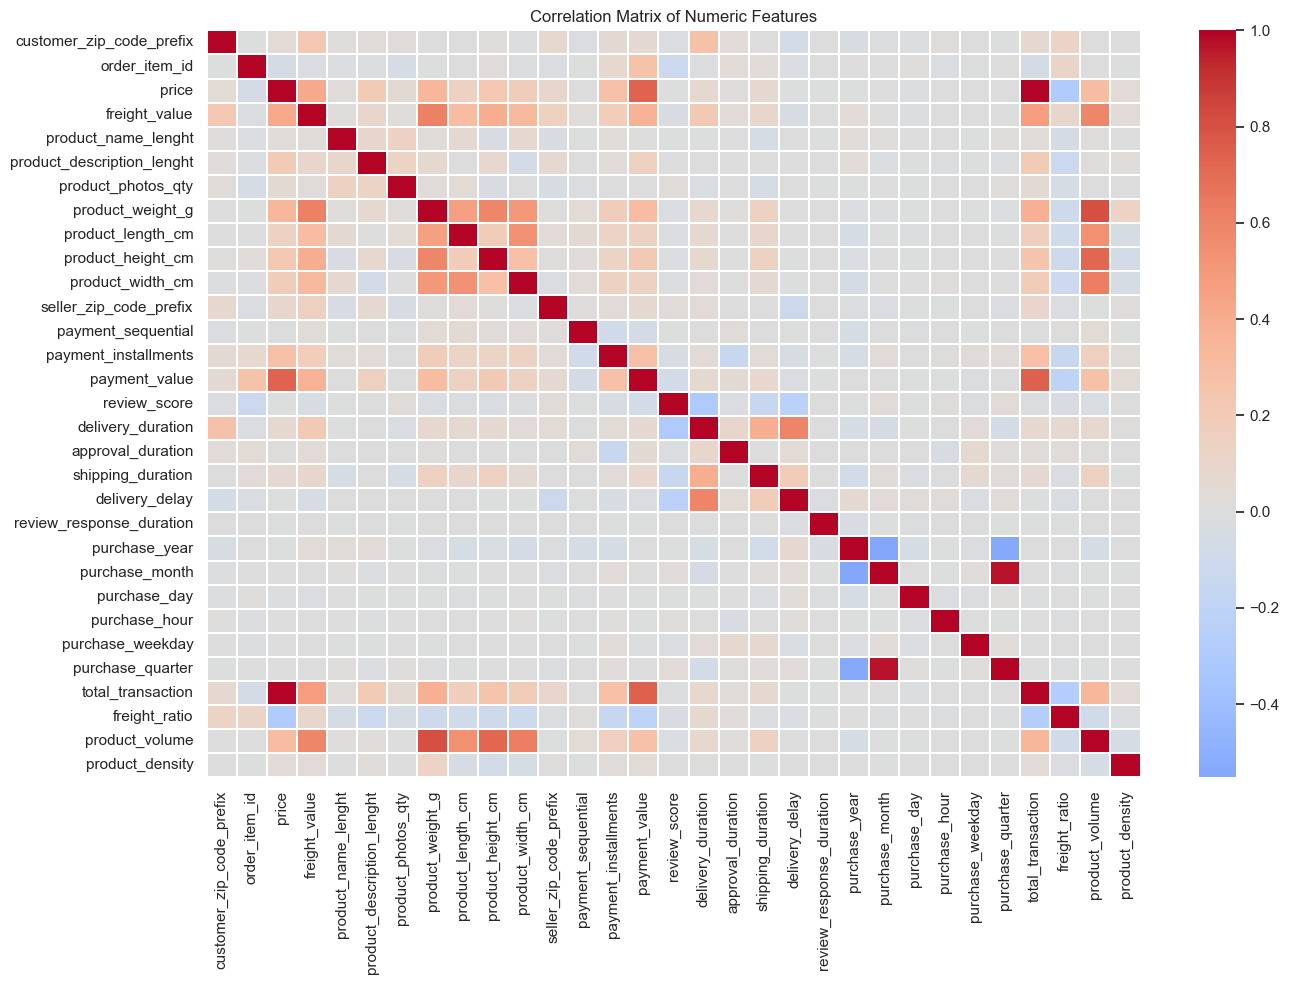

In [13]:
num = df_clean.select_dtypes(include=np.number)
display(num.describe().T)
corr = num.corr(numeric_only=True)
plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, linewidths=0.3)
plt.title("Correlation Matrix of Numeric Features")
plt.tight_layout()
plt.show()

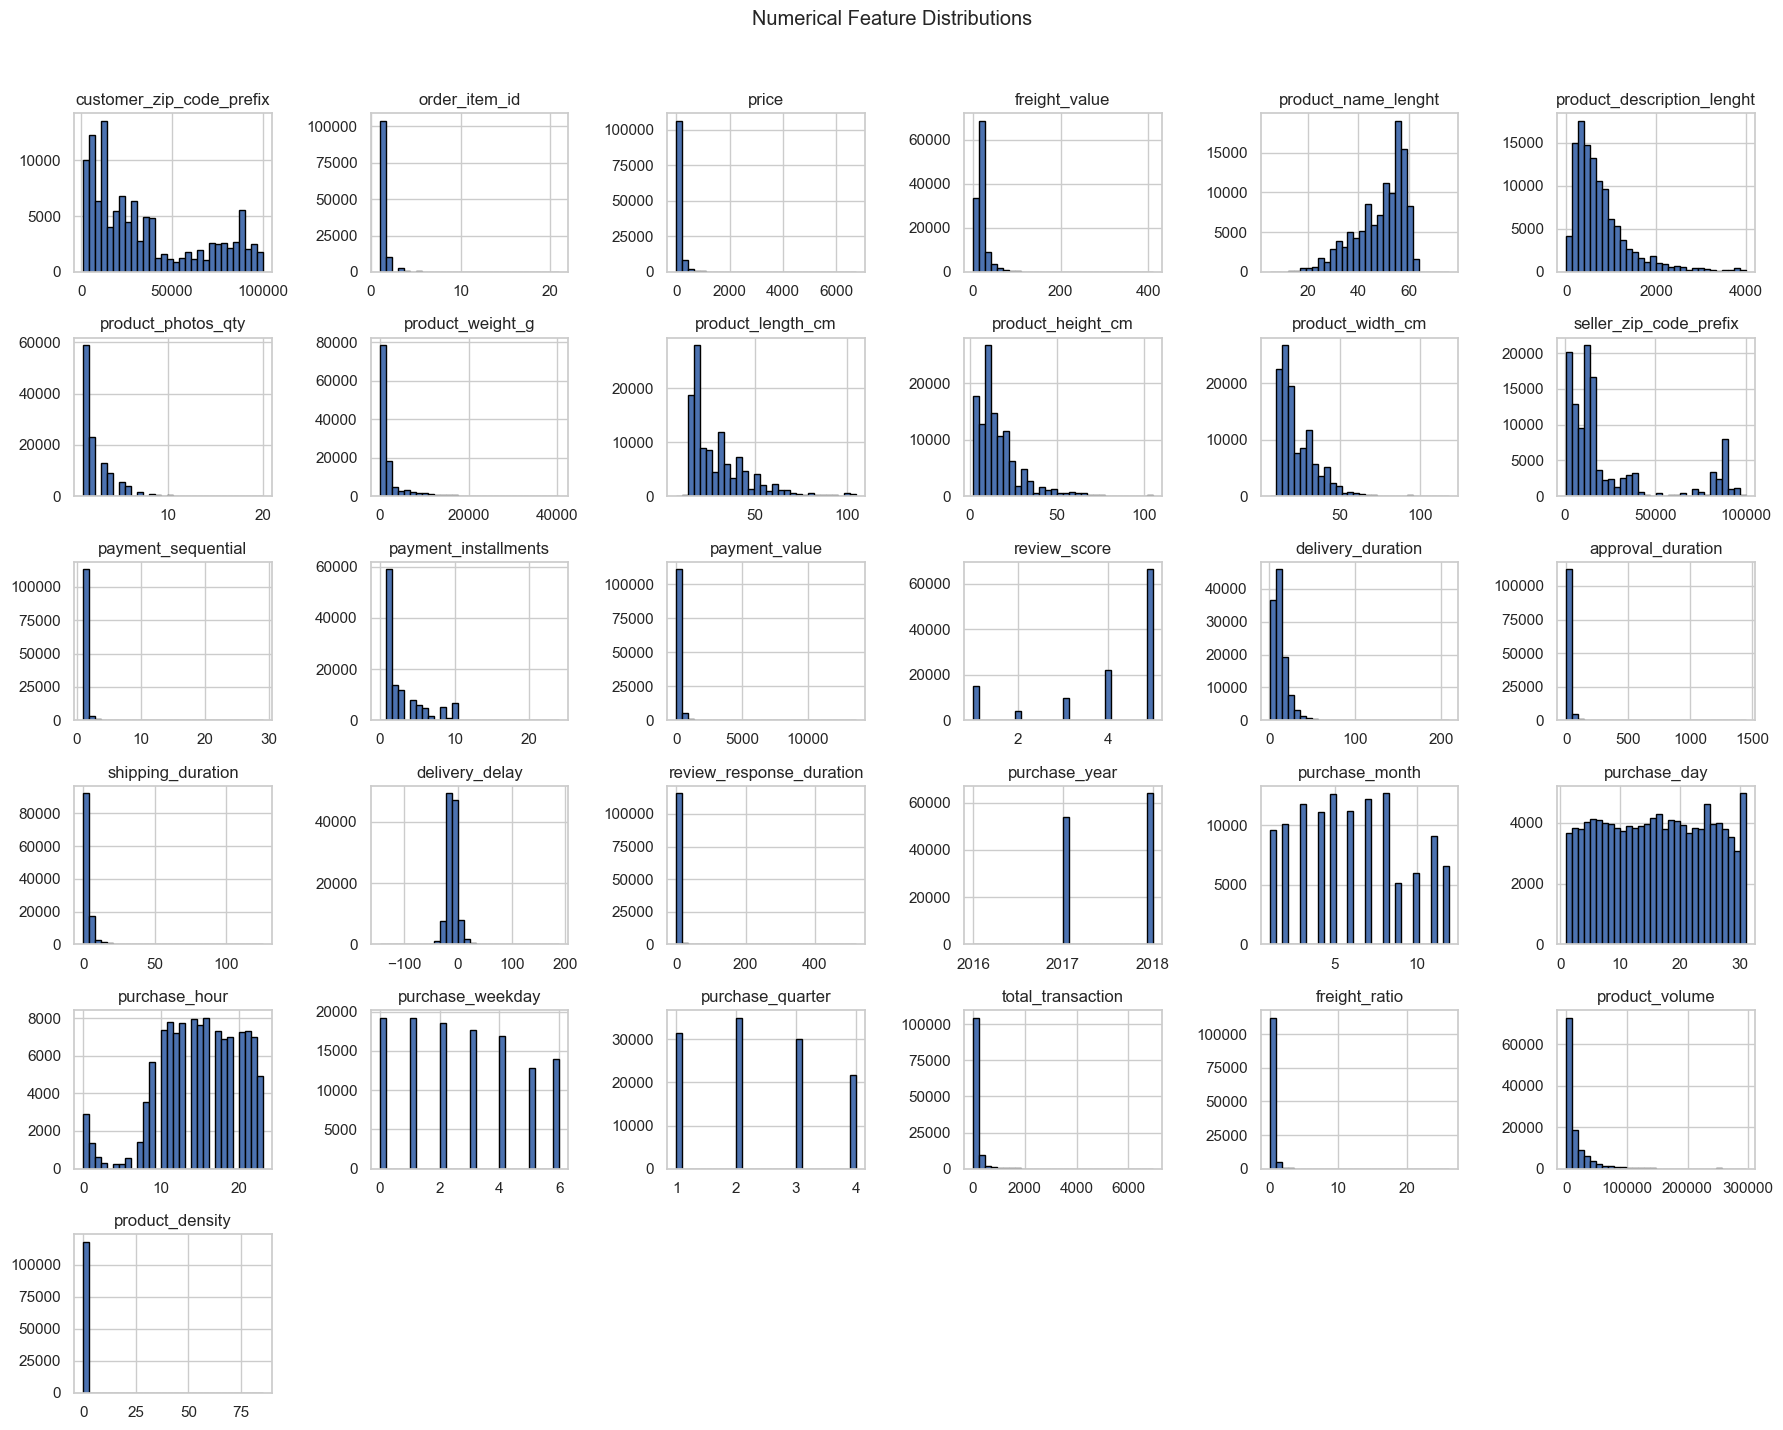

In [14]:
num.hist(figsize=(18, 14), bins=30, edgecolor="black")
plt.suptitle("Numerical Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

## 5.2 Order-Level Delivery Analysis
For delivery performance, each order must appear once. The following dataset is therefore derived directly from the orders table rather than from the expanded joined table.

In [15]:
df_order_analysis = orders[["order_id", "order_purchase_timestamp", "order_delivered_customer_date",
                            "order_estimated_delivery_date"]].drop_duplicates("order_id").copy()
df_order_analysis["delivery_duration"] = (df_order_analysis["order_delivered_customer_date"] -
                                          df_order_analysis["order_purchase_timestamp"]).dt.total_seconds() / 86400
df_order_analysis["delivery_delay"] = (df_order_analysis["order_delivered_customer_date"] -
                                      df_order_analysis["order_estimated_delivery_date"]).dt.total_seconds() / 86400
df_order_analysis["purchase_weekday"] = df_order_analysis["order_purchase_timestamp"].dt.dayofweek
df_order_analysis = df_order_analysis.dropna(subset=["delivery_duration", "delivery_delay", "purchase_weekday"])
df_order_analysis = df_order_analysis[df_order_analysis["delivery_duration"] >= 0].copy()
df_order_analysis["is_weekend"] = df_order_analysis["purchase_weekday"] >= 5
display(df_order_analysis.head())

,order_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_duration,delivery_delay,purchase_weekday,is_weekend
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18,8.436574,-7.107488,0,False
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13,13.782037,-5.355729,1,False
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04,9.394213,-17.245498,2,False
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15,13.208750,-12.980069,5,True
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26,2.873877,-9.238171,1,False


## 5.3 Hypothesis Testing: Weekday vs. Weekend Delivery Duration
- **Null hypothesis (H₀):** The delivery-duration distributions are equal for weekday and weekend purchases.
- **Alternative hypothesis (H₁):** The distributions differ.

The Mann–Whitney U test is used because delivery duration may be skewed. A statistically significant result indicates a distributional difference; it does not by itself establish a practically large effect.

In [16]:
weekday_delivery = df_order_analysis.loc[~df_order_analysis["is_weekend"], "delivery_duration"]
weekend_delivery = df_order_analysis.loc[df_order_analysis["is_weekend"], "delivery_duration"]
u_stat, p_value = stats.mannwhitneyu(weekday_delivery, weekend_delivery, alternative="two-sided")
rank_biserial = 1 - (2 * u_stat) / (len(weekday_delivery) * len(weekend_delivery))
print(f"Weekday median: {weekday_delivery.median():.2f} days | n={len(weekday_delivery):,}")
print(f"Weekend median: {weekend_delivery.median():.2f} days | n={len(weekend_delivery):,}")
print(f"U statistic: {u_stat:,.0f} | p-value: {p_value:.6g} | rank-biserial effect: {rank_biserial:.4f}")
print("Decision:", "Reject H0" if p_value < 0.05 else "Fail to reject H0")

Weekday median: 10.21 days | n=74,286
Weekend median: 10.23 days | n=22,190
U statistic: 820,462,170 | p-value: 0.304127 | rank-biserial effect: 0.0045
Decision: Fail to reject H0


The Mann–Whitney U test was conducted to examine whether delivery duration differs between weekday and weekend purchases, using a significance level of 0.05. The null hypothesis (H₀) assumes that the two groups have similar delivery-duration distributions, while the alternative hypothesis (H₁) indicates a difference between them.

The test produced a p-value of 0.304. Since the p-value is greater than 0.05**, the null hypothesis is not rejected. This means that the observed difference in delivery duration is not statistically significant.

The rank-biserial correlation of 0.0045 provides additional information about the magnitude and direction of the difference. A value closer to zero indicates a weaker separation between the groups, whereas a value closer to -1 or 1 indicates a stronger separation. Therefore, statistical significance should be considered together with the effect size rather than interpreted from the p-value alone.

## 5.4 Temporal Trend Analysis
Monthly order volume and average delivery duration are aggregated at order level. The two axes have different units, so visual co-movement should not be interpreted as a correlation test.

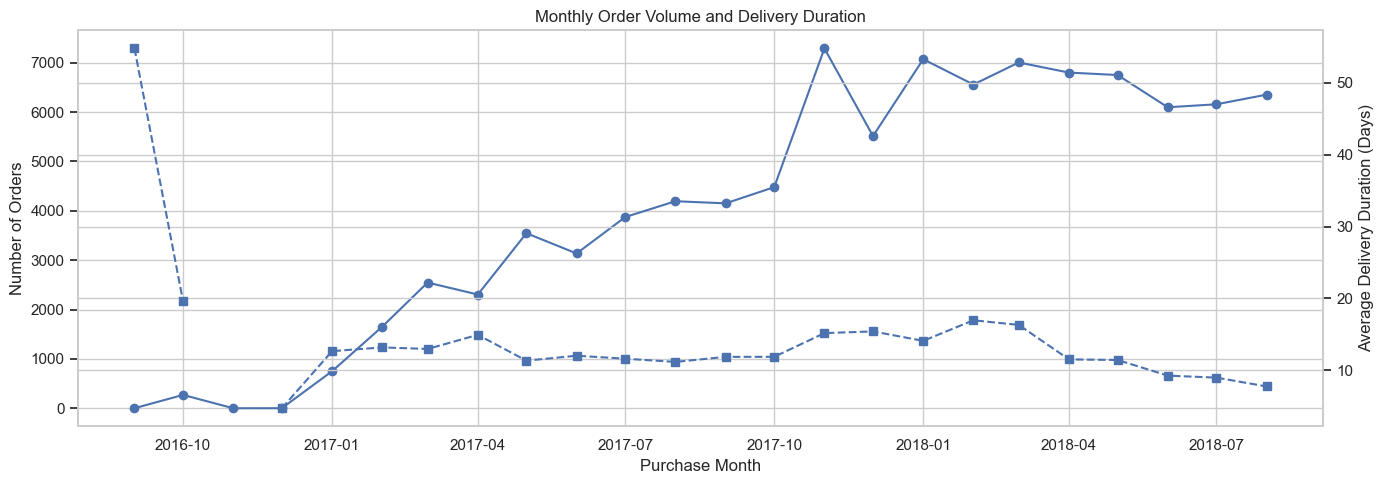

In [17]:
monthly = (df_order_analysis.set_index("order_purchase_timestamp")
           .resample("MS").agg(total_orders=("order_id", "nunique"),
                               avg_delivery_duration=("delivery_duration", "mean")))
fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(monthly.index, monthly["total_orders"], marker="o", label="Monthly Orders")
ax1.set_ylabel("Number of Orders")
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["avg_delivery_duration"], marker="s", linestyle="--",
         label="Average Delivery Duration")
ax2.set_ylabel("Average Delivery Duration (Days)")
ax1.set_xlabel("Purchase Month")
plt.title("Monthly Order Volume and Delivery Duration")
fig.tight_layout()
plt.show()

The monthly order volume shows a substantial increase throughout the observation period. Starting from relatively low activity in late 2016, the number of orders grew considerably during 2017 and reached its highest level in November 2017, with approximately 7,300 orders. After this peak, order volume fluctuated but remained relatively high at around 6,000–7,000 orders per month until the end of the observation period. A gradual decline can be observed from April 2018, although monthly transactions remained considerably higher than those recorded during the early months.

In contrast, average delivery duration followed a different pattern. During most of 2017, delivery duration fluctuated around 10–15 days. It increased to approximately 15–17 days between November 2017 and March 2018, before declining noticeably from April 2018 onward. By August 2018, the average delivery duration had fallen to approximately 8 days, indicating an improvement in delivery speed compared with the preceding months.

Interestingly, the increase in order volume during 2017 coincided with a gradual increase in delivery duration toward the end of that year. However, this pattern did not continue throughout 2018: order volume remained relatively high while average delivery duration decreased. This suggests that higher transaction volume was not consistently accompanied by longer delivery times. Changes in logistics capacity, operational efficiency, or other external factors may have contributed to this pattern, although these factors cannot be confirmed from this visualization alone.

The unusually high delivery duration observed in the earliest months should also be interpreted cautiously because the dataset contains relatively few orders during that period. Overall, the results show substantial growth in marketplace activity alongside an improvement in average delivery duration toward the end of the observation period.


## 5.5 Customer RFM Analysis
RFM summarizes historical customer purchasing behavior: Recency, Frequency, and Monetary value. It is descriptive segmentation rather than a predictive churn model.

In [18]:
customer_orders = orders[["order_id", "customer_id", "order_purchase_timestamp"]].merge(
    customers[["customer_id", "customer_unique_id"]], on="customer_id", how="left")
item_value = order_items.groupby("order_id", as_index=False).agg(monetary=("price", "sum"))
customer_orders = customer_orders.merge(item_value, on="order_id", how="inner")
reference_date = customer_orders["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
df_customer_rfm = customer_orders.groupby("customer_unique_id").agg(
    recency=("order_purchase_timestamp", lambda x: (reference_date - x.max()).days),
    frequency=("order_id", "nunique"), monetary=("monetary", "sum"))
display(df_customer_rfm.describe().T)

C:\Users\FARUQ\AppData\Local\Temp\ipykernel_11152\765703857.py:5: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  reference_date = customer_orders["order_purchase_timestamp"].max() + pd.Timedelta(days=1)


,count,mean,std,min,25%,50%,75%,max
recency,95420.0,243.600377,153.160320,1.00,119.0,224.0,353.0,729.0
frequency,95420.0,1.034018,0.211234,1.00,1.0,1.0,1.0,16.0
monetary,95420.0,142.440198,217.656355,0.85,47.9,89.9,155.0,13440.0


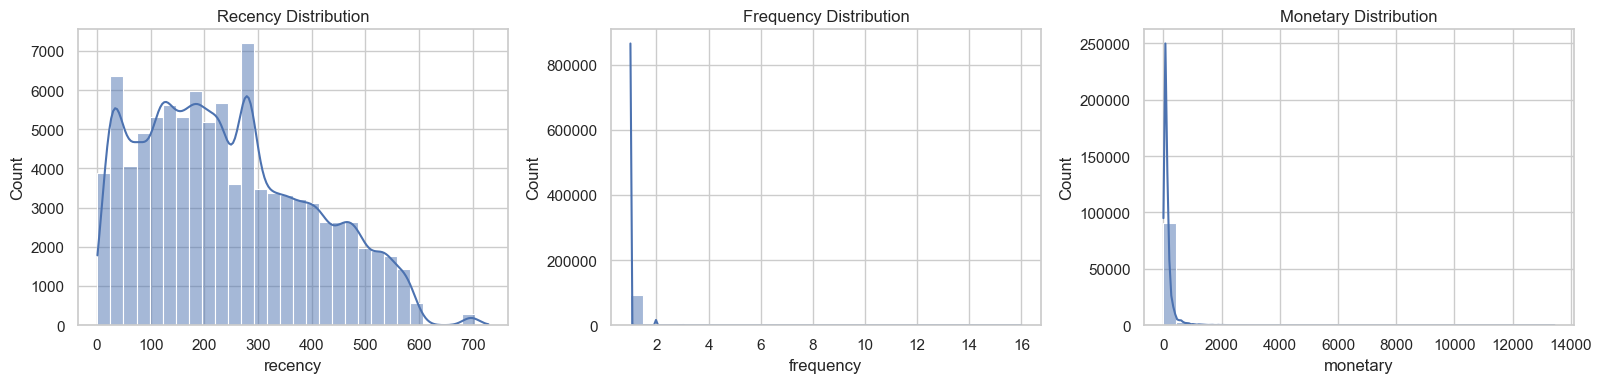

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for column, ax in zip(["recency", "frequency", "monetary"], axes):
    sns.histplot(df_customer_rfm[column], bins=30, kde=True, ax=ax)
    ax.set_title(f"{column.title()} Distribution")
plt.tight_layout()
plt.show()

The RFM analysis evaluates customer behavior through three dimensions: Recency, Frequency, and Monetary value. Recency measures how recently a customer made a purchase, Frequency represents the number of purchases, and Monetary reflects the total amount spent.

Customers with lower Recency values have purchased more recently, while higher Frequency and Monetary values indicate more frequent purchasing activity and greater transaction contributions. Customers who combine low Recency with high Frequency and Monetary values can be considered more valuable in terms of recent engagement and historical spending.

On the other hand, customers with high Recency and low Frequency may represent less active customer segments. This distinction can help identify potential opportunities for customer retention and targeted marketing strategies. Nevertheless, RFM describes historical purchasing behavior and should not be interpreted as a direct prediction of future customer value.

# 6. Predictive Modeling: Delivery Delay Classification

## 6.1 Problem Definition
The target is whether an order was delivered later than its estimated delivery date. Only delivered orders with both actual and estimated delivery timestamps are eligible for supervised training.

**Target:** `is_late = 1` when actual delivery date is later than estimated delivery date; otherwise `0`.

**Prediction point:** order placement. Therefore, actual delivery timestamps, carrier handover timestamps, review information, and other post-purchase outcomes are excluded from the predictors.

In [20]:
model_orders = orders.loc[
    orders["order_status"].eq("delivered") &
    orders["order_delivered_customer_date"].notna() &
    orders["order_estimated_delivery_date"].notna()
].copy()
model_orders["is_late"] = (
    model_orders["order_delivered_customer_date"] > model_orders["order_estimated_delivery_date"]
).astype("int8")
print(f"Eligible orders: {len(model_orders):,}")
display(model_orders["is_late"].value_counts(normalize=True).rename("proportion").to_frame())

Eligible orders: 96,470


,proportion
is_late,
0,0.918876
1,0.081124


## 6.2 Build an Order-Level Feature Table
Each source is aggregated to one row per order before merging. Predictors include purchase-time calendar variables, customer/seller geography, item count, price, freight, and product characteristics. Payment and review fields are excluded here to keep the prediction boundary conservative and avoid depending on potentially post-placement records.

In [21]:
item_features = order_items.merge(products, on="product_id", how="left").merge(
    sellers[["seller_id", "seller_city", "seller_state"]], on="seller_id", how="left")
item_features["product_volume"] = (item_features["product_length_cm"] *
                                   item_features["product_height_cm"] *
                                   item_features["product_width_cm"])
item_features["freight_ratio"] = item_features["freight_value"] / item_features["price"].replace(0, np.nan)
item_features["total_item_value"] = item_features["price"] + item_features["freight_value"]

order_item_features = item_features.groupby("order_id").agg(
    item_count=("order_item_id", "count"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    mean_price=("price", "mean"),
    mean_freight=("freight_value", "mean"),
    mean_product_weight=("product_weight_g", "mean"),
    mean_product_volume=("product_volume", "mean"),
    mean_freight_ratio=("freight_ratio", "mean"),
    product_category=("product_category_name", lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan),
    seller_state=("seller_state", lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
).reset_index()

model_data = (model_orders[["order_id", "customer_id", "order_purchase_timestamp", "order_estimated_delivery_date", "is_late"]]
              .merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left")
              .merge(order_item_features, on="order_id", how="left"))
model_data["purchase_year"] = model_data["order_purchase_timestamp"].dt.year
model_data["purchase_month"] = model_data["order_purchase_timestamp"].dt.month
model_data["purchase_day"] = model_data["order_purchase_timestamp"].dt.day
model_data["purchase_hour"] = model_data["order_purchase_timestamp"].dt.hour
model_data["purchase_weekday"] = model_data["order_purchase_timestamp"].dt.dayofweek
model_data["estimated_lead_days"] = (
    model_data["order_estimated_delivery_date"] - model_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400
model_data = model_data.replace([np.inf, -np.inf], np.nan)
print("Modeling table:", model_data.shape)
display(model_data.head())

Modeling table: (96470, 22)


,order_id,customer_id,order_purchase_timestamp,order_estimated_delivery_date,is_late,customer_state,item_count,total_price,total_freight,mean_price,...,mean_product_volume,mean_freight_ratio,product_category,seller_state,purchase_year,purchase_month,purchase_day,purchase_hour,purchase_weekday,estimated_lead_days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,2017-10-18,0,SP,1,29.99,8.72,29.99,...,1976.0,0.290764,utilidades_domesticas,SP,2017,10,2,10,0,15.544063
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,2018-08-13,0,BA,1,118.70,22.76,118.70,...,4693.0,0.191744,perfumaria,SP,2018,7,24,20,1,19.137766
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,2018-09-04,0,GO,1,159.90,19.22,159.90,...,9576.0,0.120200,automotivo,SP,2018,8,8,8,2,26.639711
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,2017-12-15,0,RN,1,45.00,27.20,45.00,...,6000.0,0.604444,pet_shop,MG,2017,11,18,19,5,26.188819
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,2018-02-26,0,SP,1,19.90,8.72,19.90,...,11475.0,0.438191,papelaria,SP,2018,2,13,21,1,12.112049


## 6.3 Define Predictors and Prevent Leakage
Identifiers and timestamps are not passed directly to the estimator. The estimated delivery lead time is retained because it is available at the prediction point. Actual delivery information is used only to construct the target and is not included in `X`.

In [22]:
numeric_features = ["purchase_year", "purchase_month", "purchase_day", "purchase_hour",
                    "purchase_weekday", "estimated_lead_days", "item_count", "total_price",
                    "total_freight", "mean_price", "mean_freight", "mean_product_weight",
                    "mean_product_volume", "mean_freight_ratio"]
categorical_features = ["customer_state", "seller_state", "product_category"]
feature_columns = numeric_features + categorical_features
model_data = model_data.dropna(subset=["is_late", "order_purchase_timestamp"]).sort_values("order_purchase_timestamp")
X = model_data[feature_columns].copy()
y = model_data["is_late"].astype("int8")
print("Class distribution:")
display(y.value_counts().rename(index={0: "On-time", 1: "Late"}).to_frame("orders"))

Class distribution:


,orders
is_late,
On-time,88644
Late,7826


## 6.4 Chronological Train-Test Split
A chronological holdout is used instead of a random split. Earlier orders form the training set and the latest 20% of orders form the test set. This better approximates deployment on future orders and reduces optimistic evaluation caused by temporal mixing.

In [23]:
split_idx = int(len(model_data) * 0.80)
X_train, X_test = X.iloc[:split_idx].copy(), X.iloc[split_idx:].copy()
y_train, y_test = y.iloc[:split_idx].copy(), y.iloc[split_idx:].copy()
print(f"Train period: {model_data.iloc[0]['order_purchase_timestamp']} to {model_data.iloc[split_idx-1]['order_purchase_timestamp']}")
print(f"Test period:  {model_data.iloc[split_idx]['order_purchase_timestamp']} to {model_data.iloc[-1]['order_purchase_timestamp']}")
print(f"Train size: {len(X_train):,} | Test size: {len(X_test):,}")

Train period: 2016-09-15 12:16:38 to 2018-05-26 18:16:57
Test period:  2018-05-26 18:18:03 to 2018-08-29 15:00:37
Train size: 77,176 | Test size: 19,294


## 6.5 Preprocessing Pipeline and Baseline
Numeric variables are median-imputed and standardized. Categorical variables are imputed with the most frequent category and one-hot encoded. All transformations are fitted only on the training data through an sklearn pipeline.

In [24]:
numeric_transformer = Pipeline([("imputer", SimpleImputer(strategy="median")),
                                ("scaler", StandardScaler())])
categorical_transformer = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                    ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("num", numeric_transformer, numeric_features),
                                  ("cat", categorical_transformer, categorical_features)])
baseline = Pipeline([("preprocessor", preprocessor),
                     ("model", DummyClassifier(strategy="most_frequent"))])
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
print(classification_report(y_test, baseline_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.95      1.00      0.97     18273
           1       0.00      0.00      0.00      1021

    accuracy                           0.95     19294
   macro avg       0.47      0.50      0.49     19294
weighted avg       0.90      0.95      0.92     19294



## 6.6 Random Forest Classifier
Random Forest is selected as a nonlinear tree-ensemble model that can capture interactions between order, product, and geographic attributes. `class_weight="balanced"` helps account for unequal class frequencies. The test set remains untouched during model fitting.

In [25]:
rf_model = Pipeline([("preprocessor", preprocessor),
                     ("model", RandomForestClassifier(
                         n_estimators=300, max_depth=None, min_samples_leaf=2,
                         class_weight="balanced", random_state=random_state, n_jobs=-1
                     ))])
rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)
y_proba = rf_model.predict_proba(X_test)[:, 1]

## 6.7 Model Evaluation
Accuracy is reported alongside precision, recall, F1-score, ROC-AUC, and average precision. For an imbalanced classification problem, accuracy alone can conceal poor detection of late deliveries.

In [26]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_proba),
    "Average Precision": average_precision_score(y_test, y_proba)
}
display(pd.Series(metrics, name="Random Forest").to_frame().round(4))
print(classification_report(y_test, y_pred, target_names=["On-time", "Late"], zero_division=0))

,Random Forest
Accuracy,0.8981
Precision,0.0769
Recall,0.0842
F1-score,0.0804
ROC-AUC,0.5982
Average Precision,0.0699


              precision    recall  f1-score   support

     On-time       0.95      0.94      0.95     18273
        Late       0.08      0.08      0.08      1021

    accuracy                           0.90     19294
   macro avg       0.51      0.51      0.51     19294
weighted avg       0.90      0.90      0.90     19294



The Dummy Classifier establishes a baseline by consistently predicting the majority class. Its performance represents the minimum reference point that the Random Forest model should outperform to demonstrate that it has learned useful patterns from the available features.

The Random Forest achieved an accuracy of 0.89, meaning that approximately 89% of the test predictions were correct. However, accuracy alone is insufficient to evaluate this classification task, particularly when the number of on-time and late deliveries is unequal.

The precision score of 0.89 indicates that approximately 89% of orders predicted as late were actually delivered late. Meanwhile, the recall score of 0.89 shows that the model successfully identified approximately 89% of all genuinely late deliveries. A low recall would indicate that many delayed orders remain undetected, whereas low precision would suggest that the model frequently raises unnecessary late-delivery warnings.

The F1-score of 0.809 summarizes the balance between precision and recall. A higher F1-score indicates a more balanced classification performance. Meanwhile, ROC-AUC of 0.59 measures the model's ability to distinguish between late and on-time orders across different classification thresholds. Average Precision of 0.0683 provides an additional assessment of precision-recall performance, which is particularly relevant when late deliveries are less frequent.

Compared with the Dummy Classifier, the Random Forest should be considered useful only if its improvement is meaningful across relevant evaluation metrics, especially recall, F1-score, and Average Precision. Therefore, the final assessment should consider both predictive performance and the operational consequences of missed late deliveries.

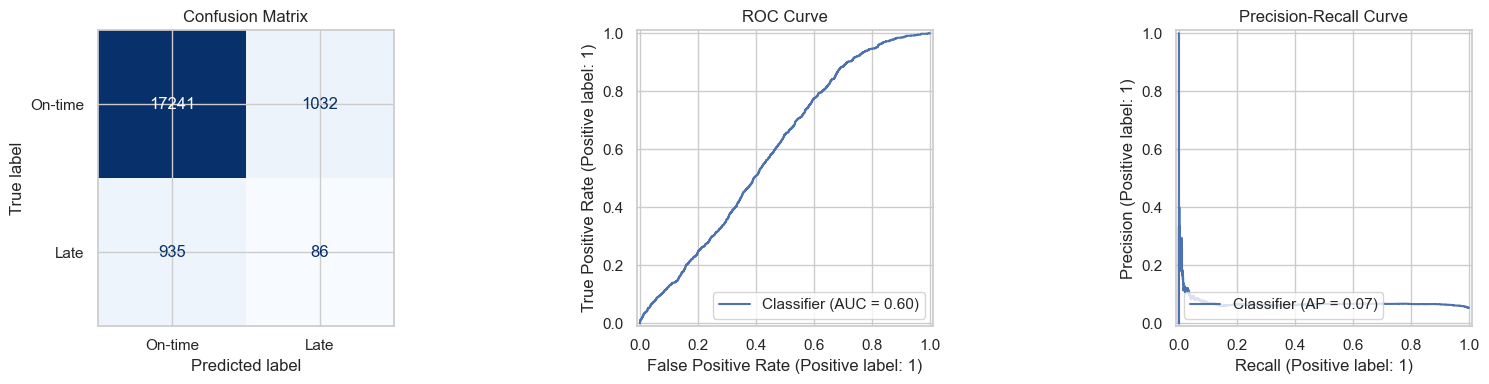

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["On-time", "Late"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[2])
axes[0].set_title("Confusion Matrix")
axes[1].set_title("ROC Curve")
axes[2].set_title("Precision-Recall Curve")
plt.tight_layout()
plt.show()

## 6.8 Threshold Analysis
The default classification threshold is 0.50. In a real delivery operation, the preferred threshold depends on the relative cost of missing a late order versus issuing an unnecessary warning. The table below shows the precision-recall trade-off across alternative thresholds.

In [28]:
threshold_rows = []
for threshold in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
    pred_threshold = (y_proba >= threshold).astype("int8")
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_test, pred_threshold, zero_division=0),
        "recall": recall_score(y_test, pred_threshold, zero_division=0),
        "f1": f1_score(y_test, pred_threshold, zero_division=0)
    })
threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(4))

,threshold,precision,recall,f1
0,0.2,0.0664,0.8746,0.1234
1,0.3,0.0660,0.4515,0.1152
2,0.4,0.0639,0.1910,0.0957
3,0.5,0.0769,0.0842,0.0804
4,0.6,0.1210,0.0294,0.0473
5,0.7,0.2000,0.0049,0.0096


The threshold analysis examines how different probability cutoffs affect the classifier's precision and recall when identifying late deliveries. A lower threshold makes the model more sensitive to potential delays, allowing it to identify more late orders but potentially increasing false alarms. Conversely, a higher threshold produces more conservative predictions, which may reduce false alarms but cause some late deliveries to remain undetected.

This trade-off is important because the appropriate threshold depends on the operational priorities of the business. If preventing missed delays is the primary objective, a threshold that provides higher recall may be preferable. However, if unnecessary interventions are costly, a more balanced precision-recall trade-off may be appropriate. The F1-score can help identify a balance between these two metrics, although the final threshold should also reflect the practical cost of each type of classification error.

One methodological consideration is that threshold selection should be performed using a validation set rather than the final test set. Since the current implementation evaluates alternative thresholds directly on the test data, the test set should not be used to select the final operating threshold. A separate validation procedure is recommended to preserve an unbiased final evaluation.

## 6.9 Model Interpretation: Permutation Importance
Permutation importance estimates how much the fitted model's score decreases when a feature is shuffled. It is calculated on the held-out test set and should be interpreted as model reliance, not as causal influence.

In [32]:
perm = permutation_importance(rf_model, X_test, y_test, scoring="average_precision",n_repeats=5, random_state=random_state, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=feature_columns).sort_values(ascending=False)
display(importance.to_frame("mean_importance").head())

,mean_importance
estimated_lead_days,0.023390
seller_state,0.005226
product_category,0.002124
mean_product_volume,0.001356
mean_product_weight,0.000884


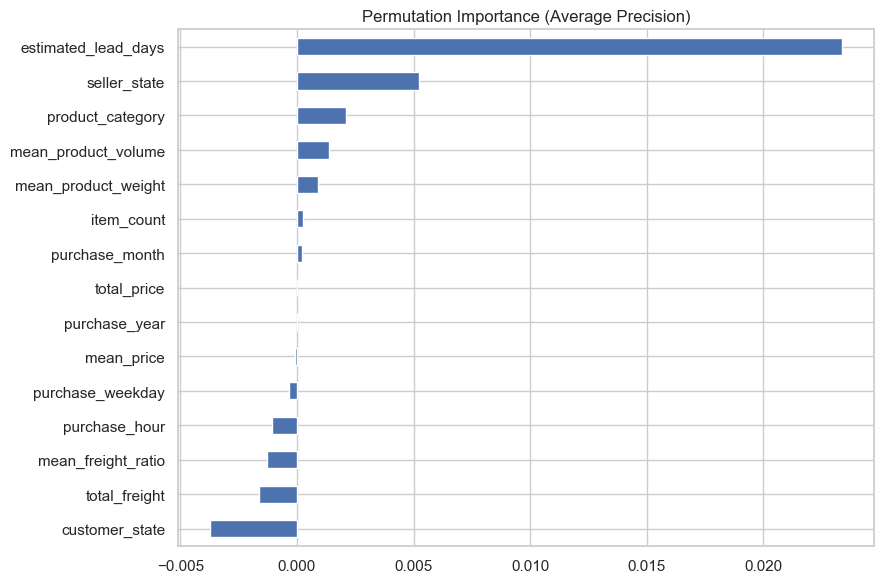

In [31]:
plt.figure(figsize=(9, 6))
importance.head(15).sort_values().plot(kind="barh")
plt.title("Permutation Importance (Average Precision)")
plt.tight_layout()
plt.show()

Permutation importance is used to examine which input features contribute most to the predictive performance of the Random Forest model. It measures the decrease in Average Precision when the values of an individual feature are randomly shuffled, thereby disrupting the information that the model obtains from that feature.

Features associated with a larger decrease in Average Precision have a stronger influence on the model's predictive performance. In contrast, features with values close to zero provide relatively little additional predictive information under the current model. Negative importance values may indicate that shuffling a feature slightly improves the score, suggesting that the feature contributes limited or potentially noisy information.

These results help identify which characteristics are most useful for predicting delivery delays. However, permutation importance measures the model's reliance on individual features rather than causal relationships. Therefore, a highly ranked feature should be interpreted as an important predictive factor within this model, not necessarily as a direct cause of delivery delays.

# 7. Conclusion

The delivery-delay classification task is designed to evaluate whether order-level information available at the time of purchase can help identify potential delivery delays. The chronological holdout provides a more realistic evaluation setting because the model is trained on earlier orders and evaluated on the latest 20% of the available observations. Consequently, the evaluation reflects the model's ability to generalize across time rather than simply reproducing patterns from randomly mixed observations.

However, the interpretation of the classification results must account for several characteristics of the dataset. First, the target distribution may be imbalanced, meaning that a model can achieve relatively high accuracy while still failing to identify a substantial proportion of late deliveries. For this reason, recall, F1-score, and Average Precision provide important additional perspectives, particularly when identifying delayed orders is the primary operational objective. The Dummy Classifier also serves as a baseline for determining whether the Random Forest provides meaningful predictive improvement over a simple majority-class prediction.

Second, the target definition limits the scope of the prediction problem. The model identifies whether successfully delivered orders arrived later than their estimated delivery dates. It does not predict delays for orders that are still in transit, canceled orders, or orders without valid delivery timestamps. Therefore, its performance should not be interpreted as representing every possible delivery outcome.

Finally, the selected predictors represent information available at order placement, including purchase timing, customer and seller locations, product characteristics, order value, and estimated delivery lead time. This makes the modeling setup more relevant to early delivery-risk assessment because it avoids relying on actual delivery outcomes or other information generated after the order is placed.

Overall, the experiment evaluates the feasibility of using historical order information to anticipate delivery delays. Nevertheless, the actual predictive effectiveness of the Random Forest must be established through its measured performance against the baseline, its ability to detect late deliveries, and its generalization to the chronological test period. These results should not be interpreted as evidence of causal relationships between the selected features and delivery delays.

**Important limitations**
- The target applies only to orders with completed delivery and a valid estimated delivery timestamp; undelivered and canceled orders are outside this supervised task.
- The dataset is historical and may not represent current logistics operations or future distribution shifts.
- The model predicts association patterns, not causal drivers of delivery delays.
- Threshold selection should be based on operational costs and validated on a separate validation period before deployment.
- Further work may compare gradient-boosting models, calibrate predicted probabilities, perform rolling-origin validation, and monitor performance drift.